<a href="https://colab.research.google.com/github/tonygruyichich-glitch/Python_Workshop/blob/main/AB_Testing/A_B_Testing_with_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A/B Testing with Python

## 🎯 Project Goal

In this project, we will analyze a simple A/B test to answer one business question:

> **Does the new landing page increase the conversion rate compared with the old landing page?**

We will use Python and statistics to:

* Explore and clean the data
* Compare the Control and Treatment groups
* Calculate conversion rates
* Measure the difference between the groups
* Test whether the difference is statistically significant
* Interpret the results from a business perspective

---

## 📊 About the Data

Each row represents a user who participated in the experiment.

| Column         | Description                           |
| -------------- | ------------------------------------- |
| `user_id`      | Unique user identifier                |
| `timestamp`    | Time of the user's visit              |
| `group`        | `control` or `treatment`              |
| `landing_page` | `old_page` or `new_page`              |
| `converted`    | `0` = No conversion, `1` = Conversion |

### Experiment Groups

**Control** → Users assigned to the existing landing page

**Treatment** → Users assigned to the new landing page

Our main metric is the **Conversion Rate**.

---

## 📚 Notebook Outline

1. **Business Question** — Define what we want to measure.
2. **Load the Data** — Import the data and inspect it.
3. **Data Quality** — Check for missing values, duplicates, and invalid records.
4. **Prepare the Data** — Keep only valid experiment records.
5. **Descriptive Analysis** — Calculate users, conversions, and conversion rates.
6. **Visualization** — Compare the two groups visually.
7. **Statistical Hypotheses** — Define \(H_0\) and \(H_1\).
8. **Statistical Testing** — Test the difference using two methods:

   * **Two-Proportion Z-Test** — chosen because we are comparing the conversion rates of two independent groups.
   * **Chi-Square Test** — chosen because `group` and `converted` are categorical variables, allowing us to test whether they are associated.
9. **p-value & Significance** — Decide whether the observed difference is statistically significant.
10. **Effect Size / Lift** — Measure how large the difference is.
11. **Business Interpretation** — Translate the results into a business conclusion.

---

## 🚀 Let's Begin

We will move step by step from **data → statistics → business insight**.


# Step 1 — Business Question

Our goal is to determine whether the **new landing page** performs better than the **old landing page**.

### Business Question

> **Does the new landing page increase the conversion rate?**

We will compare two groups:

* **Control** → old landing page
* **Treatment** → new landing page

Our main metric will be the **Conversion Rate**.


# Step 2 — Load the Data

In this step, we will import the libraries we need and load the A/B testing data into a Pandas DataFrame.

We will also take a quick look at the data to understand its structure.


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/python_workshop/ab_data_user_convertions.csv"

df = pd.read_csv(file_path)

df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


# Step 3 — Initial Exploratory Data Analysis (EDA)

In this step, we will explore the structure of the dataset and examine the main variables used in the A/B test.

We will check the data types, unique values, and distribution of the experiment groups and conversion results.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB


as we can see we have 294K observations. we have no nulls anywhere in the data. timestamp column in in object datatype which I dont like for its purpose. I will cast it to datetime in order to use dt accessor later.

In [ ]:
#casting timestamp to datetime type
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   user_id       294478 non-null  int64         
 1   timestamp     294478 non-null  datetime64[ns]
 2   group         294478 non-null  object        
 3   landing_page  294478 non-null  object        
 4   converted     294478 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 11.2+ MB


Check Unique Values in Key Variables

In [ ]:
print('num of groups','->'*15,df["group"].nunique())
print('num of landing pages','->'*15,df["landing_page"].nunique())
print('num of converted','->'*15,df["converted"].nunique())


num of groups ->->->->->->->->->->->->->->-> 2
num of landing pages ->->->->->->->->->->->->->->-> 2
num of converted ->->->->->->->->->->->->->->-> 2


In [ ]:
print(df["group"].unique())
print(df["landing_page"].unique())
print(df["converted"].unique())



['control' 'treatment']
['old_page' 'new_page']
[0 1]


In [ ]:
#Check the Distribution of Experiment Groups
df["group"].value_counts()


,count
group,
treatment,147276
control,147202


In [ ]:
#Check the Distribution of Conversion Results
df["converted"].value_counts()

,count
converted,
0,259241
1,35237


In [ ]:
#Check the Distribution of landing page
df["landing_page"].value_counts()


,count
landing_page,
old_page,147239
new_page,147239


In [ ]:
#Check for Duplicate Users
df["user_id"].duplicated().sum()


np.int64(3894)

### ⚠️ Duplicate Users

Some users appear more than once in the dataset, with different timestamps and sometimes different experiment groups or landing pages.

This can cause the same user to be counted multiple times and may distort our analysis.

**Each user should appear only once in the final dataset.**


In [ ]:
df[df["user_id"].duplicated(keep=False)].sort_values("user_id").head(20)

,user_id,timestamp,group,landing_page,converted
213114,630052,2017-01-07 12:25:54.089486,treatment,old_page,1
230259,630052,2017-01-17 01:16:05.208766,treatment,new_page,0
251762,630126,2017-01-19 17:16:00.280440,treatment,new_page,0
22513,630126,2017-01-14 13:35:54.778695,treatment,old_page,0
11792,630137,2017-01-22 14:59:22.051308,control,new_page,0
183371,630137,2017-01-20 02:08:49.893878,control,old_page,0
255753,630320,2017-01-12 05:27:37.181803,treatment,old_page,0
207211,630320,2017-01-07 18:02:43.626318,control,old_page,0
110634,630471,2017-01-23 01:42:51.501851,control,old_page,0
96929,630471,2017-01-07 02:14:17.405726,control,new_page,0


### ⚠️ Data Quality Issue

Not every user was shown the landing page that matches their experiment group.

Some users in the **Control** group were shown the `new_page`, while some users in the **Treatment** group were shown the `old_page`.

Before calculating the conversion rate, we need to **remove these invalid records** so that each group contains only the users who were exposed to the intended page.


In [ ]:
#Compare Experiment Groups and Landing Pages
pd.crosstab(df["group"], df["landing_page"])

landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145311,1965


# Step 4 — Data Quality & Cleaning

In this step, we will fix the data quality issues identified during our initial exploration.

We will:

* Remove records where the `group` and `landing_page` do not match
* Remove duplicate users
* Prepare a clean dataset for the A/B test analysis



### ⚠️ The Order Matters

The order of the cleaning steps is important. We will **first remove invalid experiment records** and only then handle duplicate users.

This ensures that when we choose which occurrence of a user to keep, we are choosing from **valid experiment records only**.

After cleaning, each user should appear only once and belong to the correct experiment group

##Remove Invalid Experiment Records

In [ ]:
df = df[
    ((df["group"] == "control") & (df["landing_page"] == "old_page")) |
    ((df["group"] == "treatment") & (df["landing_page"] == "new_page"))
]

## Remove Duplicate Users

### ⚠️ Think Before You Delete

Removing duplicate users is important, but **how we remove them matters just as much**.

We should not delete duplicates blindly. The rule should be based on the question we are trying to answer.

For example, we could:

* Keep the **first appearance** → represents the user's initial interaction.
* Keep the **last appearance** → represents the user's most recent interaction.

### How do we choose?

We choose the rule based on the **business question and the meaning of the data**.

In our A/B test, we will keep the **first valid interaction of each user**, because we want to analyze the user's initial exposure to the experiment and whether they converted during that interaction.


In [ ]:
df = df.sort_values("timestamp").drop_duplicates("user_id", keep="first")
df = df.reset_index(drop=True)

In [ ]:
df

,user_id,timestamp,group,landing_page,converted
0,922696,2017-01-02 13:42:05.378582,treatment,new_page,0
1,781507,2017-01-02 13:42:15.234051,control,old_page,0
2,737319,2017-01-02 13:42:21.786186,control,old_page,0
3,818377,2017-01-02 13:42:26.640581,treatment,new_page,0
4,725857,2017-01-02 13:42:27.851110,treatment,new_page,0
...,...,...,...,...,...
290579,799244,2017-01-24 13:41:15.325359,treatment,new_page,0
290580,808330,2017-01-24 13:41:19.152664,control,old_page,0
290581,843121,2017-01-24 13:41:44.097174,treatment,new_page,0
290582,836373,2017-01-24 13:41:52.604673,control,old_page,0


In [ ]:
#check if all the duplicates are gone
df["user_id"].duplicated().sum()

np.int64(0)

lets check if we still have wrong data

In [ ]:
#we have no wrong data!!
pd.crosstab(df["group"], df["landing_page"])

landing_page,new_page,old_page
group,,
control,0,145274
treatment,145310,0


# Step 5 — Descriptive Analysis

In this step, we will summarize the results of the experiment for each group.

We will calculate:

* Number of users
* Number of conversions
* Conversion rate

This will give us a first look at the difference between the Control and Treatment groups before performing statistical tests.


In [ ]:
#sample 5000 rows from df
sample = df.sample(5000, random_state=42)
summary_sample = sample.groupby("group").agg(
    users=("user_id", "count"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean")
)

In [ ]:
summary = df.groupby("group").agg(
    users=("user_id", "count"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean")
)

summary

,users,conversions,conversion_rate
group,,,
control,145274,17489,0.120386
treatment,145310,17264,0.118808


In [ ]:
control_rate = summary.loc["control", "conversion_rate"]
treatment_rate = summary.loc["treatment", "conversion_rate"]

difference = treatment_rate - control_rate

difference

np.float64(-0.0015782389853555567)

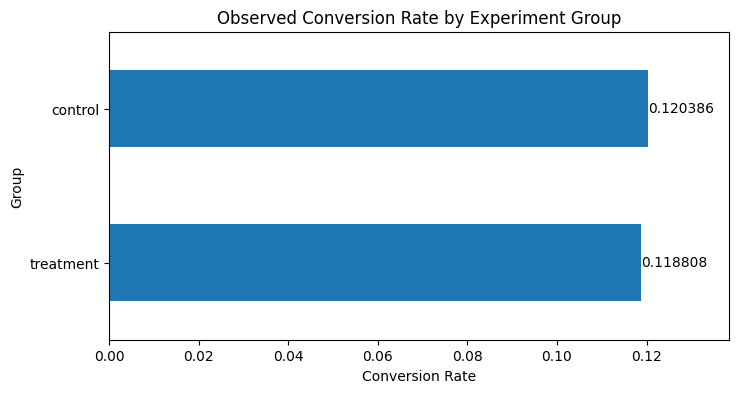

In [ ]:
import matplotlib.pyplot as plt

rates = summary["conversion_rate"].sort_values()

ax = rates.plot(
    kind="barh",
    figsize=(8, 4)
)

plt.title("Observed Conversion Rate by Experiment Group")
plt.xlabel("Conversion Rate")
plt.ylabel("Group")

ax.bar_label(
    ax.containers[0]
)

plt.xlim(0, rates.max() * 1.15)
plt.show()

### 🔎 What Did We Find?

The **Control group had a slightly higher conversion rate than the Treatment group**.

The observed difference was approximately **0.16 percentage points**.

At this stage, we are only describing what we see in our sample. We **have not yet tested whether this difference is statistically significant** or could simply be the result of random variation.

Next, we will use statistical testing to investigate whether the observed difference provides enough evidence of a real difference between the groups.


# Step 6 — Statistical Hypotheses

We observed a small difference in conversion rates between the Control and Treatment groups.

Now we will translate our business question into statistical hypotheses and test whether the observed difference could be due to random variation.

### Null Hypothesis (H₀)

There is **no difference** in conversion rates between the two groups.

**H₀: p_control = p_treatment**

### Alternative Hypothesis (H₁)

There **is a difference** in conversion rates between the two groups.

**H₁: p_control ≠ p_treatment**

In the next step, we will use statistical tests to evaluate these hypotheses.


## Two-Proportion Z-Test


A **Two-Proportion Z-Test** is a statistical hypothesis test used to determine whether there is a statistically significant difference between the proportions (percentages or rates) of two independent groups.

When to Use It?
Use this test when measuring a binary categorical variable (e.g., success/failure, yes/no, clicked/didn't click) across two separate groups to check if the success rate in one group differs significantly from the other.


In our case, we compare the conversion rates of the Control and Treatment groups.

The Z-statistic is calculated as:

**Z = (p₁ - p₂) / √[ p̂(1 - p̂) × (1/n₁ + 1/n₂) ]**

Where:

- **p₁** → conversion rate of Group 1
- **p₂** → conversion rate of Group 2
- **n₁, n₂** → number of users in each group
- **p̂** → pooled conversion rate across both groups

The pooled conversion rate is:

**p̂ = (x₁ + x₂) / (n₁ + n₂)**

where **x₁** and **x₂** are the numbers of conversions in the two groups.

### Python

The `proportions_ztest()` function performs this calculation for us.

It receives:

- the number of conversions in each group
- the number of users in each group

and returns:

- **Z-statistic** → the standardized difference between the two proportions
- **p-value** → how likely it would be to observe a difference this large, assuming the Null Hypothesis is true

In [ ]:
from statsmodels.stats.proportion import proportions_ztest

conversions = [
    summary.loc["control", "conversions"],
    summary.loc["treatment", "conversions"]
]

users = [
    summary.loc["control", "users"],
    summary.loc["treatment", "users"]
]

z_stat, p_value = proportions_ztest(conversions, users)

print("Z-statistic:", z_stat)
print("p-value:", p_value)

Z-statistic: 1.3109241984234394
p-value: 0.18988337448195103



The Two-Proportion Z-Test gave us:

* **Z-statistic:** 1.31
* **p-value:** 0.190

Our significance level is **α = 0.05**.

Since the **p-value (0.190) is greater than α (0.05)**, we **fail to reject the Null Hypothesis**.

Based on this test, we do not have enough statistical evidence to conclude that the conversion rates of the Control and Treatment groups are different.

The small difference we observed in our sample could reasonably be explained by **random variation**.

> **Important:** This does not mean that the two conversion rates are exactly equal. It means that the observed difference is **not statistically significant at the 5% significance level**.


###  Understanding the Z-Statistic Direction

The **sign of the Z-statistic depends on the order of the groups we provide to the test**.

In our test, we provided:

```python
conversions = [control_conversions, treatment_conversions]
users = [control_users, treatment_users]
```

Therefore, the test calculates the difference as:

**Control − Treatment**

Since the Control conversion rate is slightly higher than the Treatment conversion rate, the difference is positive and our **Z-statistic is positive (1.31)**.

A positive Z does **not** mean that the Treatment group performed better. It only tells us the **direction of the difference based on the order of the groups in the test**.

For example:

- **Positive Z** → Group 1 has a higher proportion than Group 2
- **Negative Z** → Group 1 has a lower proportion than Group 2

### What if the Z were positive and statistically significant?

Suppose we received:

**Z = 2.5**  
**p-value = 0.01**

Since the p-value is below 0.05, we would reject the Null Hypothesis.

Because the Z is positive, we would conclude that **Group 1 has a statistically significantly higher conversion rate than Group 2**.

In our experiment, that would mean the **Control group performs significantly better than the Treatment group**.

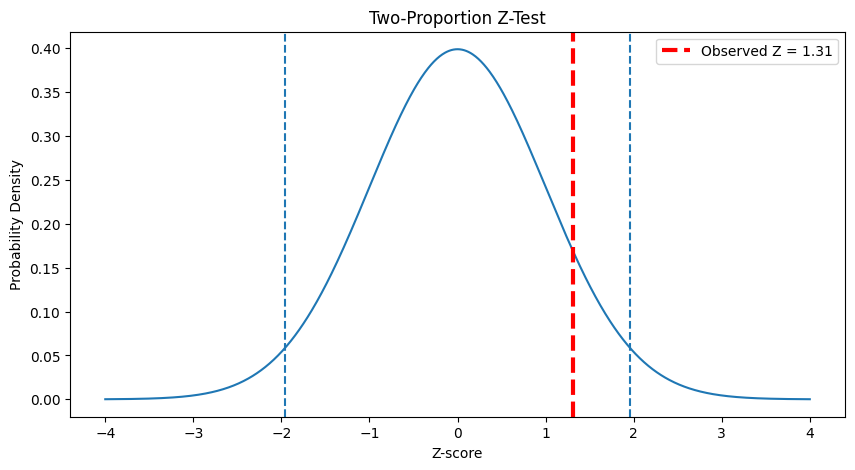

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Standard normal distribution
x = np.linspace(-4, 4, 1000)
y = norm.pdf(x)

plt.figure(figsize=(10, 5))
plt.plot(x, y)

# Critical values for alpha = 0.05
critical_value = 1.96

plt.axvline(-critical_value, linestyle="--")
plt.axvline(critical_value, linestyle="--")

# Observed Z-statistic
plt.axvline(
    z_stat,
    linestyle="--",
    linewidth=3,
    label=f"Observed Z = {z_stat:.2f}",
    color="red"
)

plt.title("Two-Proportion Z-Test")
plt.xlabel("Z-score")
plt.ylabel("Probability Density")

plt.legend()
plt.show()

##Chi-Square Test

We will now test the same hypotheses using a **Chi-Square Test**.

This test is suitable because we are examining the relationship between two categorical variables:

* `group` → Control / Treatment
* `converted` → 0 / 1

The goal is the same as before: to determine whether the difference in conversion rates between the two groups is statistically significant.


In [ ]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["group"], df["converted"])

chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)

Chi-square statistic: 1.7035660051885058
p-value: 0.19182228096235662



The Chi-Square Test gave us:

* **Chi-square statistic:** 1.704
* **p-value:** 0.192

Since the **p-value (0.192) is greater than α = 0.05**, we **fail to reject the Null Hypothesis**.

As with the Two-Proportion Z-Test, we do not have enough statistical evidence to conclude that the conversion rates of the Control and Treatment groups are different.

Both statistical methods therefore lead us to the **same conclusion**.


## Impact of Sample Size on Statistical Power

### What Happened
* **Initial Test:** Small sample $\rightarrow$ high p-value ($p > 0.05$) $\rightarrow$ failed to reject $H_0$.
* **Scaled Dataset:** Doubled observations $\rightarrow$ lower standard error $\rightarrow$ significant p-value ($p < 0.05$).

### Key Concept
Increasing sample size increases **Statistical Power**. A larger $N$ reduces standard error, turning an unobserved effect into a statistically significant result without changing the underlying effect size.

In [ ]:
#doubling the df by multiple each observation/row to two
from statsmodels.stats.proportion import proportions_ztest
import pandas as pd

# 1. Duplicate the dataset
df_doubled = pd.concat([df, df], ignore_index=True)

# 2. Aggregate the doubled data
summary_doubled = df_doubled.groupby("group").agg(
    users=("user_id", "count"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean")
)

print(summary_doubled)

# 3. Two-Proportion Z-Test
conversions = [
    summary_doubled.loc["control", "conversions"],
    summary_doubled.loc["treatment", "conversions"]
]

users = [
    summary_doubled.loc["control", "users"],
    summary_doubled.loc["treatment", "users"]
]

z_stat, p_value = proportions_ztest(conversions, users)

print("\nZ-statistic:", z_stat)
print("p-value:", p_value)

            users  conversions  conversion_rate
group                                          
control    290548        34978         0.120386
treatment  290620        34528         0.118808

Z-statistic: 1.8539267806535067
p-value: 0.06374963590233573


In [ ]:
#tripling the dataset in order to see what will be the p value now

from statsmodels.stats.proportion import proportions_ztest

# 1. Triple the dataset
df_tripled = pd.concat([df, df, df], ignore_index=True)

# 2. Aggregate
summary_tripled = df_tripled.groupby("group").agg(
    users=("user_id", "count"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean")
)
print(summary_tripled)
# 3. Two-Proportion Z-Test
conversions = [
    summary_tripled.loc["control", "conversions"],
    summary_tripled.loc["treatment", "conversions"]
]

users = [
    summary_tripled.loc["control", "users"],
    summary_tripled.loc["treatment", "users"]
]

z_stat, p_value = proportions_ztest(conversions, users)

print("Z-statistic:", z_stat)
print("p-value:", p_value)

            users  conversions  conversion_rate
group                                          
control    435822        52467         0.120386
treatment  435930        51792         0.118808
Z-statistic: 2.270587316540902
p-value: 0.02317197199369444
